# 04 - Clustering K-Means

**Objectif** : regrouper les individus en profils financiers homogènes, puis déterminer le nombre de groupes le plus pertinent.

**Données** : `data/raw/genz_money_spends1.csv` (1 700 individus, 14 variables).

**Résultats produits** (lus par la page « 5. Clustering K-Means » de l'application) :
- `data/processed/dataset_with_kmeans_clusters.csv` : données avec les clusters (k = 4 et k optimal)
- `data/results/kmeans_metrics_by_k.csv` et `kmeans_optimal_k_results.json` : métriques pour k = 2 à 10
- `data/results/clustering_standardization_info.json` : paramètres de standardisation
- 4 graphiques `kmeans_*.png`

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
DATA = Path("../data")
RAW, PROCESSED, RESULTS = DATA / "raw", DATA / "processed", DATA / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

RANDOM_STATE = 42  # reproductibilité
N_INIT = 10

## 1. Chargement des données

In [2]:
# Jeu de données de 1 700 individus (séparateur ;)
df = pd.read_csv(RAW / "genz_money_spends1.csv", sep=";")
VARIABLES = [c for c in df.columns if c != "ID"]
X = df[VARIABLES]
print(df.shape, "| valeurs manquantes :", int(df.isna().sum().sum()))
X.describe().T.round(1)

(1700, 15) | valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
Age,1700.0,22.5,2.9,18.0,20.0,22.0,25.0,27.0
Income (USD),1700.0,4764.8,1877.1,1501.0,3149.8,4743.0,6419.8,7994.0
Rent (USD),1700.0,1155.6,495.2,300.0,724.0,1157.5,1589.8,1999.0
Groceries (USD),1700.0,357.1,142.6,100.0,237.0,362.0,482.2,599.0
Eating Out (USD),1700.0,272.1,131.8,50.0,157.0,266.5,387.2,499.0
Entertainment (USD),1700.0,209.1,109.6,20.0,113.0,210.0,303.2,399.0
Subscription Services (USD),1700.0,55.9,26.1,10.0,33.0,57.0,79.0,99.0
Education (USD),1700.0,1009.9,576.6,0.0,518.5,995.0,1513.5,1996.0
Online Shopping (USD),1700.0,362.9,197.1,20.0,191.0,370.0,539.0,699.0
Savings (USD),1700.0,1557.4,818.4,100.0,891.0,1563.5,2222.2,2999.0


## 2. Standardisation

K-Means repose sur des distances euclidiennes : sans standardisation, les revenus (en milliers) écraseraient l'âge (en dizaines). Les paramètres sont sauvegardés pour pouvoir standardiser un nouvel individu de la même façon.

In [3]:
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

with open(RESULTS / "clustering_standardization_info.json", "w", encoding="utf-8") as f:
    json.dump({"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
               "variables": VARIABLES}, f, ensure_ascii=False, indent=2)

## 3. K-Means avec k = 4

Première segmentation avec 4 groupes, visualisée sur deux variables clés : revenus et épargne. Les croix sont les centres des groupes.

In [4]:
kmeans_4 = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_scaled)
df["Cluster_KMeans"] = kmeans_4.labels_
centers_4 = pd.DataFrame(scaler.inverse_transform(kmeans_4.cluster_centers_), columns=VARIABLES)
print(df["Cluster_KMeans"].value_counts().sort_index())


def plot_2d(labels, centers, k, filename):
    fig, ax = plt.subplots(figsize=(9, 7))
    sc = ax.scatter(df["Income (USD)"], df["Savings (USD)"], c=labels, cmap="viridis", s=10, alpha=0.6)
    ax.scatter(centers["Income (USD)"], centers["Savings (USD)"], c="red", marker="X", s=250,
               edgecolor="black", label="Centroïdes")
    ax.set_xlabel("Income (USD)")
    ax.set_ylabel("Savings (USD)")
    ax.set_title(f"Clusters K-Means (k={k}) : Income vs Savings")
    ax.legend()
    plt.colorbar(sc, label="Cluster")
    plt.savefig(RESULTS / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_2d(kmeans_4.labels_, centers_4, 4, "kmeans_clusters_2d.png")

Cluster_KMeans
0    374
1    481
2    418
3    427
Name: count, dtype: int64


<Figure size 900x700 with 2 Axes>

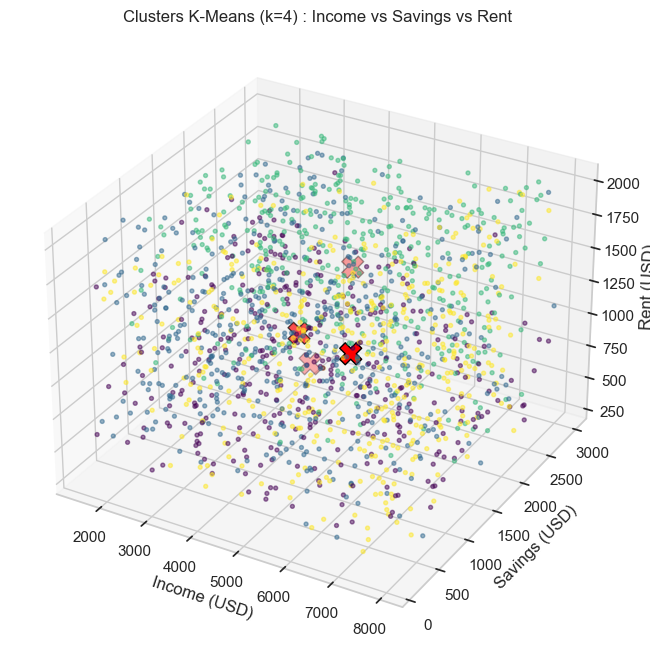

In [5]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(df["Income (USD)"], df["Savings (USD)"], df["Rent (USD)"], c=kmeans_4.labels_,
           cmap="viridis", s=8, alpha=0.5)
ax.scatter(centers_4["Income (USD)"], centers_4["Savings (USD)"], centers_4["Rent (USD)"],
           c="red", marker="X", s=250, edgecolor="black")
ax.set_xlabel("Income (USD)")
ax.set_ylabel("Savings (USD)")
ax.set_zlabel("Rent (USD)")
ax.set_title("Clusters K-Means (k=4) : Income vs Savings vs Rent")
plt.savefig(RESULTS / "kmeans_clusters_3d.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Nombre optimal de clusters

Pour k = 2 à 10, on calcule trois indicateurs :
- **Inertie** (méthode du coude) : le coude est le k où la baisse d'inertie ralentit le plus (maximum de la dérivée seconde)
- **Silhouette** : plus elle est haute, mieux les groupes sont séparés
- **Calinski-Harabasz** : rapport variance inter / intra-groupes, plus haut = mieux

In [6]:
k_values = list(range(2, 11))
inertias, silhouettes, calinskis = [], [], []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, model.labels_))
    calinskis.append(calinski_harabasz_score(X_scaled, model.labels_))

metrics = pd.DataFrame({"k": k_values, "Inertie (WSS)": inertias,
                        "Silhouette Score": silhouettes, "Calinski-Harabasz Index": calinskis})
metrics.to_csv(RESULTS / "kmeans_metrics_by_k.csv", index=False)
metrics.round(4)

,k,Inertie (WSS),Silhouette Score,Calinski-Harabasz Index
0,2,22472.6693,0.0549,100.2910
1,3,21590.4983,0.0499,86.8327
2,4,20890.6823,0.0490,78.7305
3,5,20317.8480,0.0502,72.6239
4,6,19834.8602,0.0502,67.7287
5,7,19409.1481,0.0512,63.8334
6,8,18990.2651,0.0532,61.2199
7,9,18685.9728,0.0519,57.8497
8,10,18383.7783,0.0537,55.3230


Coude : k=3 | Silhouette : k=2 | Calinski-Harabasz : k=2
k recommandé : 2


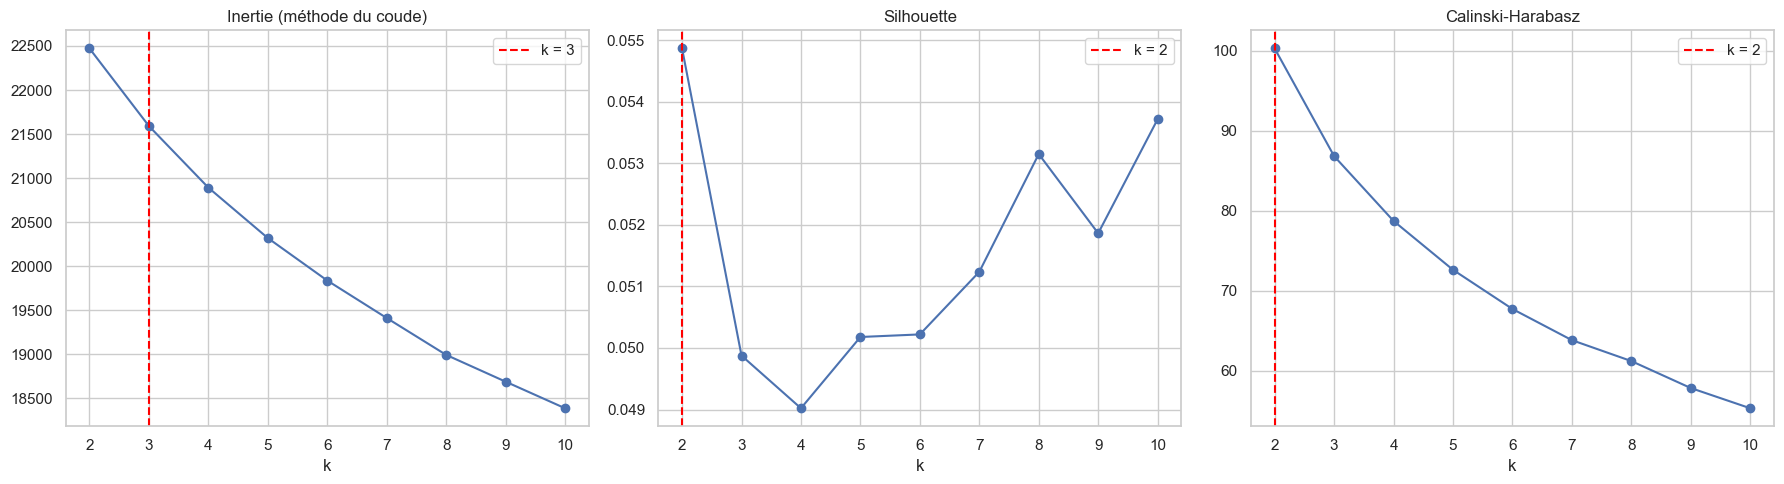

In [7]:
k_elbow = k_values[int(np.argmax(np.diff(inertias, 2))) + 1]
k_silhouette = k_values[int(np.argmax(silhouettes))]
k_calinski = k_values[int(np.argmax(calinskis))]
# Silhouette et Calinski-Harabasz mesurent directement la qualité des groupes : on suit leur choix
k_recommended = k_silhouette if k_silhouette == k_calinski else k_elbow
print(f"Coude : k={k_elbow} | Silhouette : k={k_silhouette} | Calinski-Harabasz : k={k_calinski}")
print(f"k recommandé : {k_recommended}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, values, title, best in [(ax[0], inertias, "Inertie (méthode du coude)", k_elbow),
                               (ax[1], silhouettes, "Silhouette", k_silhouette),
                               (ax[2], calinskis, "Calinski-Harabasz", k_calinski)]:
    a.plot(k_values, values, marker="o")
    a.axvline(best, color="red", linestyle="--", label=f"k = {best}")
    a.set_xlabel("k")
    a.set_title(title)
    a.legend()
plt.tight_layout()
plt.savefig(RESULTS / "kmeans_optimal_k_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

with open(RESULTS / "kmeans_optimal_k_results.json", "w", encoding="utf-8") as f:
    json.dump({"k_elbow": k_elbow, "k_silhouette": k_silhouette, "k_calinski": k_calinski,
               "k_recommended": k_recommended, "max_silhouette_score": max(silhouettes),
               "max_calinski_score": max(calinskis), "inertias": inertias,
               "silhouette_scores": silhouettes, "calinski_scores": calinskis}, f, indent=2)

**Lecture** : la silhouette maximale reste très faible (environ 0,05). Les individus ne forment pas de groupes naturellement bien séparés sur ces 14 variables. La segmentation reste utile pour décrire des tendances, mais il ne faut pas la présenter comme des profils nettement distincts.

## 5. K-Means avec le k optimal

Cluster_KMeans_Optimal
0    836
1    864
Name: count, dtype: int64


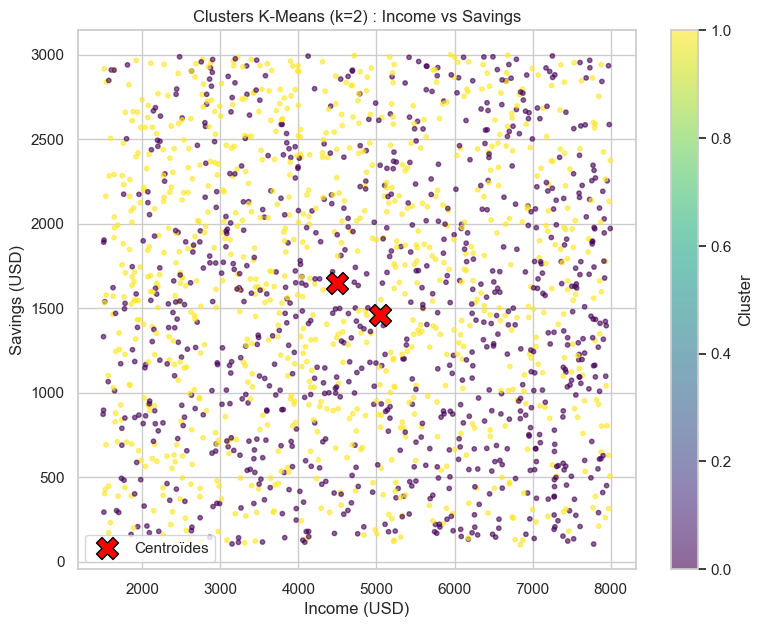

Profil moyen de chaque cluster :


,Age,Income (USD),Rent (USD),Groceries (USD),Eating Out (USD),Entertainment (USD),Subscription Services (USD),Education (USD),Online Shopping (USD),Savings (USD),Investments (USD),Travel (USD),Fitness (USD),Miscellaneous (USD)
0,22.0,5047.0,1140.0,352.0,278.0,206.0,55.0,988.0,378.0,1461.0,2472.0,1034.0,91.0,238.0
1,23.0,4491.0,1171.0,362.0,267.0,213.0,57.0,1031.0,348.0,1651.0,2430.0,1001.0,224.0,181.0


In [8]:
kmeans_opt = KMeans(n_clusters=k_recommended, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_scaled)
df["Cluster_KMeans_Optimal"] = kmeans_opt.labels_
centers_opt = pd.DataFrame(scaler.inverse_transform(kmeans_opt.cluster_centers_), columns=VARIABLES)
print(df["Cluster_KMeans_Optimal"].value_counts().sort_index())
plot_2d(kmeans_opt.labels_, centers_opt, k_recommended, "kmeans_clusters_optimal_2d.png")

print("Profil moyen de chaque cluster :")
centers_opt.round(0)

## 6. Sauvegarde

In [9]:
df.to_csv(PROCESSED / "dataset_with_kmeans_clusters.csv", index=False)
print("Sauvegardé :", PROCESSED / "dataset_with_kmeans_clusters.csv", df.shape)

Sauvegardé : ..\data\processed\dataset_with_kmeans_clusters.csv (1700, 17)
